In [33]:
import pandas as pd
import polars as pl
from datetime import datetime, timedelta
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from sklearn.ensemble import RandomForestRegressor
from sklearn.metrics import (confusion_matrix, ConfusionMatrixDisplay, accuracy_score,recall_score, precision_score,roc_curve, auc,mean_squared_error,
precision_recall_curve,log_loss,roc_auc_score,average_precision_score,f1_score)
from sklearn.model_selection import train_test_split,RepeatedKFold,cross_val_score,TimeSeriesSplit,GridSearchCV
from tqdm import tqdm
from sklearn.preprocessing import StandardScaler,MinMaxScaler,RobustScaler,OneHotEncoder
from sklearn.pipeline import Pipeline
from sklearn.compose import ColumnTransformer
from sklearn.impute import SimpleImputer
from sklearn.base import clone
from sklearn.calibration import calibration_curve
import xgboost as xgb
import os

In [34]:

data = pl.DataFrame() 
years = ["2022","2023","2024","2025"]

for y in years:
    PATH = f"../data/processed/statcast_{y}.parquet"
    data = pl.concat([data, pl.read_parquet(PATH)], how="diagonal_relaxed")

In [35]:
top20_ids = (
    data.group_by("pitcher")
        .agg(pl.len().alias("pitches"))
        .sort("pitches", descending=True)
        .head(20)
)

In [36]:
data = data.filter(pl.col("description").is_in(["called_strike"]) & 
                    pl.col("pitcher").is_in(top20_ids["pitcher"]) &
                (pl.col("plate_x").is_not_null()) &
                (pl.col("sz_top").is_not_null())
                )


C:\Users\mmcdo\AppData\Local\Temp\ipykernel_26812\1081205181.py:1: DeprecationWarning: `is_in` with a collection of the same datatype is ambiguous and deprecated.
Please use `implode` to return to previous behavior.

See https://github.com/pola-rs/polars/issues/22149 for more information.
  data = data.filter(pl.col("description").is_in(["called_strike"]) &


In [37]:
data = data.to_pandas()

In [38]:
pitch_mapping = {
    # Fastballs (Velocity & Movement variations)
    "FF": "Fastball",  # Four-Seam Fastball
    "SI": "Fastball",  # Sinker
    "FC": "Fastball",  # Cutter
    "FA": "Fastball",  # Other Fastball

    # Sliders (Horizontal movement)
    "SL": "Slider",    # TSlider
    "ST": "Slider",    # Sweeper
    "SV": "Slider",    # Slurve

    # Curveballs
    "CU": "Curveball", # Traditional Curveball
    "KC": "Curveball", # Knuckle-Curve
    "CS": "Curveball", # Slow Curve

    # Changeups
    "CH": "Changeup",  # Traditional Changeup
    "FS": "Changeup",  # Splitter (Finger-Split)
    "FO": "Changeup",  # Forkball
    "SC": "Changeup",  # Screwball (Fades opposite of a slider)

    # Junk
    "EP": "Junk",      # Eephus (Ultra-slow utility pitch)
    "KN": "Junk"       # Knuckleball
}

data["pitch_cat"] = data["pitch_type"].map(pitch_mapping)
data["count"] = data["balls"].astype(str) + "-" + data["strikes"].astype(str)
data["same_hand"] = (data["stand"] == data["p_throws"]).astype(int)
data["wrong_call"] = data["is_missed_ball"] | data["is_missed_strike"]
data['call'] = data['description']
data["month"] = pd.to_datetime(data["game_date"]).dt.month
data["zone"] = data["zone"].astype(int).astype(str) 
data["pitcher"] = data["pitcher"].astype(int).astype(str) 
data["batter"] = data["batter"].astype(int).astype(str) 
data["called_strike"] = (data["description"] == "called_strike").astype(int)

In [39]:
#data.info(verbose=True)

In [40]:
feature_cols = [
    "release_speed",
    "release_spin_rate",
    "pitch_cat",
    "zone",
    "balls",
    "strikes",
    "inning",
    "outs_when_up",
    "inning_topbot",
    "stand",
    #"p_throws",
    "n_thruorder_pitcher",
    "sz_top",
    "sz_bot",
    "called_strike",
    #"pitcher",
    #"batter",
    "pitch_number",
    "pitcher_days_since_prev_game"

]

response_col = [
    "is_missed_ball",
    #"is_missed_strike",
    #"wrong_call"
    ][0]

In [41]:
cat_cols = ["pitch_cat", "zone", "inning_topbot", "stand", "p_throws","pitcher","batter",]
for c in cat_cols:
    data[c] = data[c].astype("category")
num_cols = [c for c in feature_cols if c not in cat_cols]

In [42]:
# for p in top_pitchers:
#     print(p)
#     df = data[data["pitcher"] == p].reset_index(drop=True)
#     print(len(df))
# print(len(df))

In [43]:
cv = TimeSeriesSplit(n_splits=5)

xgb_model = xgb.XGBClassifier(
    random_state=6740,
    objective="binary:logistic",
    enable_categorical=True,
    tree_method="hist",
    eval_metric="aucpr",
    n_jobs=1, 
    scale_pos_weight=1.25 
)
pipe = Pipeline(steps=[("xgb", xgb_model)])

param_grid = {
    "xgb__n_estimators":  [100, 200],
    "xgb__learning_rate": [0.05, 0.1],
    "xgb__max_depth":     [2, 3],
    "xgb__gamma":         [0, 1],
    "xgb__reg_lambda":    [1.0, 5.0],
     "xgb__min_child_weight": [5, 20]
}

results, test_frames, train_frames = [], [], []
top_pitchers = [str(p) for p in top20_ids["pitcher"]]

for p in top_pitchers:
    df = data[data["pitcher"] == p].reset_index(drop=True)

    for c in cat_cols:
        df[c] = df[c].astype("category")

    split = int(len(df) * 0.85)
    train, test = df.iloc[:split], df.iloc[split:]

    if len(train) < 200 or train[response_col].nunique() < 2:
        print(f"skip pitcher {p}: n_train={len(train)}, y-unique={train[response_col].nunique()}")
        continue

    search = GridSearchCV(pipe, param_grid, cv=cv,
                          scoring="average_precision", n_jobs=-1)
    search.fit(train[feature_cols], train[response_col])
    print(f"{p}: best={search.best_params_}  cv_ap={search.best_score_:.4f}")
    
    #add new
    model = search.best_estimator_

    p_tr = model.predict_proba(train[feature_cols])[:, 1]
    p_te = model.predict_proba(test[feature_cols])[:, 1]

    pr, rc, th = precision_recall_curve(train[response_col], p_tr)
    target_precision = 0.75
    idx = np.argmin(np.abs(pr[:-1] - target_precision))
    thr_p = th[idx]

    results.append({
        "pitcher":        p,
        "n_train":        len(train),
        "n_test":         len(test),
        "base_rate_test": test[response_col].mean(),
        "cv_ap":          search.best_score_,
        "test_ap":        average_precision_score(test[response_col], p_te),
        "test_auc":       roc_auc_score(test[response_col], p_te),
        "test_ll":        log_loss(test[response_col], p_te),
        "thr":            thr_p,
        **{k.replace("xgb__", ""): v for k, v in search.best_params_.items()},
    })

    train_frames.append(train.assign(pred_prob=p_tr, thr=thr_p, split="train"))
    test_frames.append( test.assign(pred_prob=p_te, thr=thr_p, split="test"))

    print(f"{p}:  n_train={len(train):>5}  n_test={len(test):>4}  "
            f"cv_ap={search.best_score_:.4f}  test_ap={results[-1]['test_ap']:.4f}")

656302: best={'xgb__gamma': 0, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 1.0}  cv_ap=0.7467
656302:  n_train= 1615  n_test= 285  cv_ap=0.7467  test_ap=0.6784
657277: best={'xgb__gamma': 1, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 3, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 1.0}  cv_ap=0.7846
657277:  n_train= 2123  n_test= 375  cv_ap=0.7846  test_ap=0.8067
668678: best={'xgb__gamma': 1, 'xgb__learning_rate': 0.05, 'xgb__max_depth': 2, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 5.0}  cv_ap=0.7675
668678:  n_train= 1923  n_test= 340  cv_ap=0.7675  test_ap=0.7605
592332: best={'xgb__gamma': 0, 'xgb__learning_rate': 0.1, 'xgb__max_depth': 2, 'xgb__min_child_weight': 5, 'xgb__n_estimators': 100, 'xgb__reg_lambda': 5.0}  cv_ap=0.7684
592332:  n_train= 1692  n_test= 299  cv_ap=0.7684  test_ap=0.7528
605135: best={'xgb__gamma': 1, 'xgb__learning_rat

In [44]:
# model = search.best_estimator_

# p_tr = model.predict_proba(train[feature_cols])[:, 1]
# p_te = model.predict_proba(test[feature_cols])[:, 1]

# pr, rc, th = precision_recall_curve(train[response_col], p_tr)
# target_recall = 0.75
# idx = np.argmin(np.abs(rc[:-1] - target_recall)) 
# thr_p = th[idx]

# results.append({
#     "pitcher":        p,
#     "n_train":        len(train),
#     "n_test":         len(test),
#     "base_rate_test": test[response_col].mean(),
#     "cv_ap":          search.best_score_,
#     "test_ap":        average_precision_score(test[response_col], p_te),
#     "test_auc":       roc_auc_score(test[response_col], p_te),
#     "test_ll":        log_loss(test[response_col], p_te),
#     "thr":            thr_p,
#     **{k.replace("xgb__", ""): v for k, v in search.best_params_.items()},
# })

# train_frames.append(train.assign(pred_prob=p_tr, thr=thr_p, split="train"))
# test_frames.append( test.assign(pred_prob=p_te, thr=thr_p, split="test"))

# print(f"{p}:  n_train={len(train):>5}  n_test={len(test):>4}  "
#         f"cv_ap={search.best_score_:.4f}  test_ap={results[-1]['test_ap']:.4f}")

results_df = pd.DataFrame(results).sort_values("test_ap", ascending=False)
display(results_df)

,pitcher,n_train,n_test,base_rate_test,cv_ap,test_ap,test_auc,test_ll,thr,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda
1,657277,2123,375,0.317333,0.784627,0.806736,0.853959,0.378640,0.336231,1,0.05,3,5,100,1.0
19,607074,1466,259,0.328185,0.757237,0.778573,0.807032,0.407130,0.358149,1,0.10,3,5,100,5.0
12,621244,1821,322,0.319876,0.756848,0.764232,0.825797,0.423061,0.370261,1,0.05,2,5,100,1.0
16,571578,1504,266,0.289474,0.699953,0.762413,0.812685,0.388874,0.359798,1,0.10,3,5,100,1.0
2,668678,1923,340,0.308824,0.767455,0.760505,0.809544,0.398658,0.360313,1,0.05,2,5,100,5.0
14,642547,1392,246,0.288618,0.748585,0.756869,0.830342,0.393064,0.364811,1,0.05,2,5,100,5.0
3,592332,1692,299,0.307692,0.768447,0.752750,0.806186,0.424712,0.357591,0,0.10,2,5,100,5.0
17,579328,1497,265,0.233962,0.698541,0.747345,0.841411,0.358340,0.314486,1,0.10,3,5,100,5.0
10,656605,1794,317,0.268139,0.702631,0.723832,0.804285,0.398038,0.333567,1,0.05,3,5,100,5.0
4,605135,1972,348,0.250000,0.741959,0.716946,0.811248,0.378847,0.327801,1,0.10,3,5,100,5.0


In [45]:
all_train = pd.concat(train_frames, ignore_index=True)
all_test  = pd.concat(test_frames,  ignore_index=True)

all_train["pred_label"] = (all_train["pred_prob"] >= all_train["thr"]).astype(int)
all_test ["pred_label"] = (all_test ["pred_prob"] >= all_test ["thr"]).astype(int)

def _metrics(y, p, l, tag):
    print(f"{tag:6s} LogLoss {log_loss(y, p):.4f} | "
          f"ROC-AUC {roc_auc_score(y, p):.4f} | "
          f"PR-AUC {average_precision_score(y, p):.4f} | "
          f"F1 {f1_score(y, l):.4f} | base rate {y.mean():.3f}")

_metrics(all_train[response_col], all_train["pred_prob"], all_train["pred_label"], "Train")
_metrics(all_test [response_col], all_test ["pred_prob"], all_test ["pred_label"], "Test")


results = pd.DataFrame({
    "actual":     all_test[response_col].values,
    "pred_prob":  all_test["pred_prob"].values,
    "pred_label": all_test["pred_label"].values,
    "split":      "test",
})

Train  LogLoss 0.3756 | ROC-AUC 0.8662 | PR-AUC 0.8031 | F1 0.6808 | base rate 0.290
Test   LogLoss 0.3986 | ROC-AUC 0.8018 | PR-AUC 0.7217 | F1 0.6011 | base rate 0.270


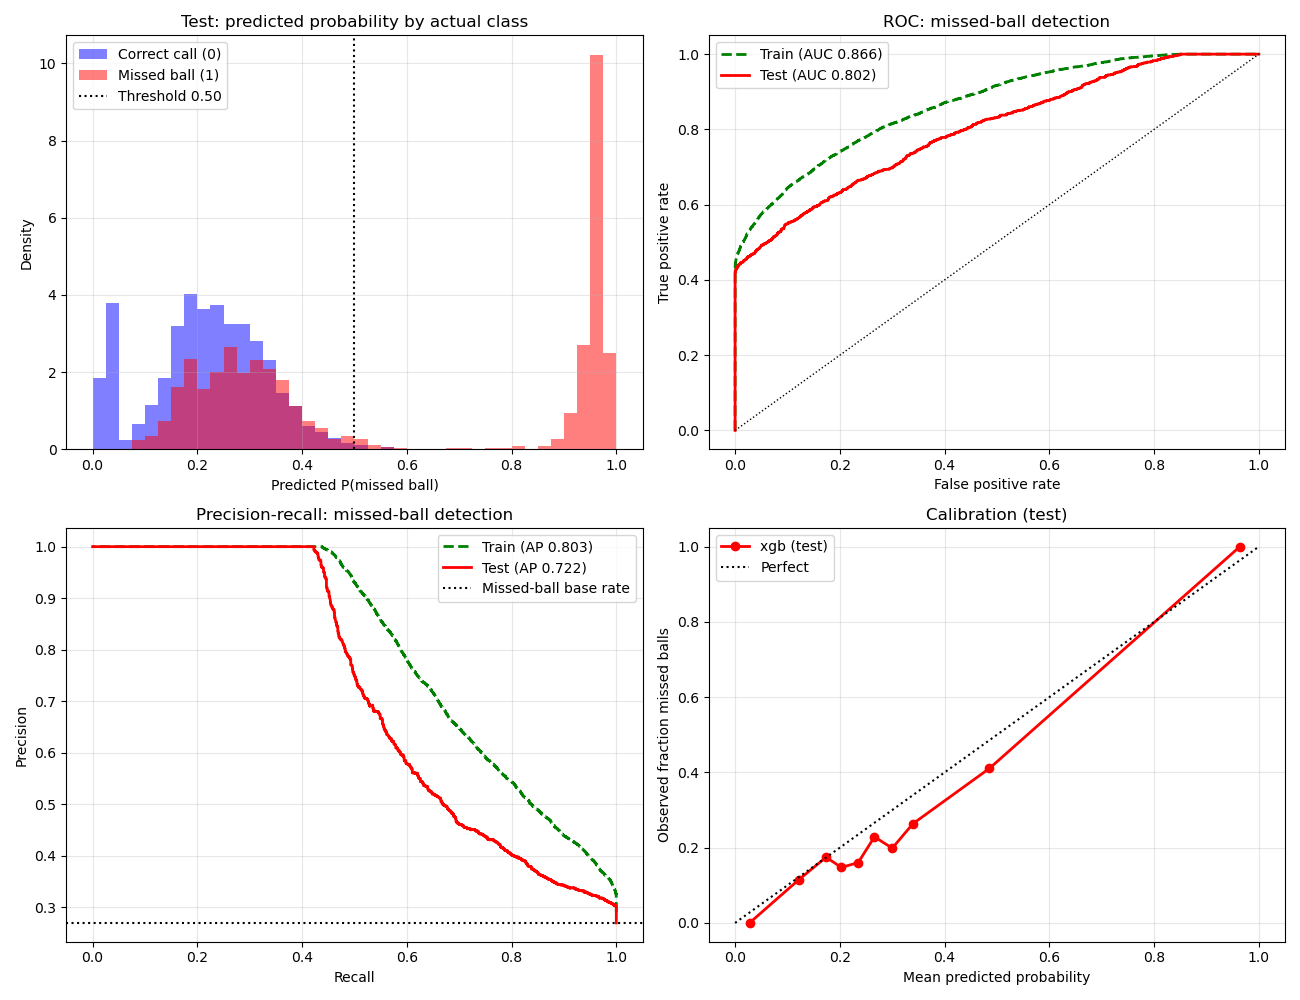

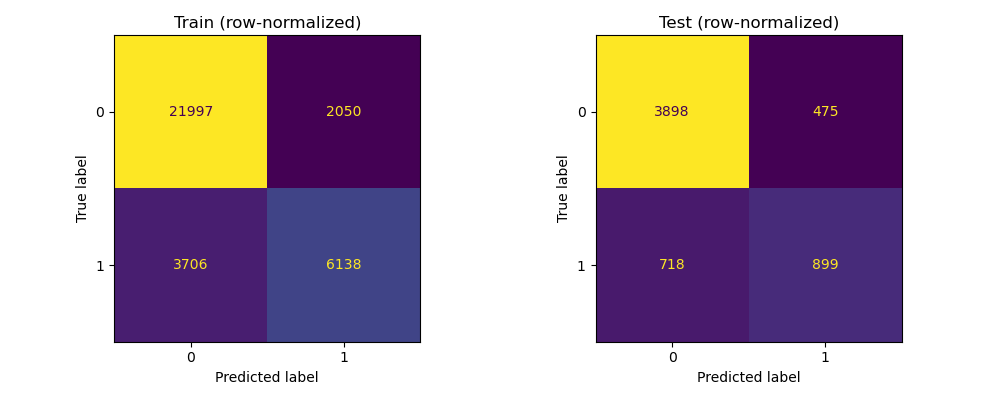

In [46]:
%matplotlib widget
fig, ax = plt.subplots(2, 2, figsize=(13, 10))
thr = 0.5
bins = np.linspace(0, 1, 41)
for cls, c, lbl in [(0, 'b', 'Correct call (0)'), (1, 'r', 'Missed ball (1)')]:
    ax[0, 0].hist(all_test["pred_prob"][all_test[response_col].values == cls], bins=bins, color=c, alpha=.5, density=True, label=lbl)
ax[0, 0].axvline(thr, color='black', linestyle=':', linewidth=1.5, label=f'Threshold {thr:.2f}')
ax[0, 0].set(xlabel='Predicted P(missed ball)', ylabel='Density', title='Test: predicted probability by actual class')
ax[0, 0].legend()

for yt, pp, st, lbl in [(all_train[response_col], all_train["pred_prob"], 'g--', 'Train'), (all_test[response_col], all_test["pred_prob"], 'r-', 'Test')]:
    f, t, _ = roc_curve(yt, pp)
    ax[0, 1].plot(f, t, st, linewidth=2, label=f'{lbl} (AUC {roc_auc_score(yt, pp):.3f})')
ax[0, 1].plot([0, 1], [0, 1], 'k:', linewidth=1)
ax[0, 1].set(xlabel='False positive rate', ylabel='True positive rate', title='ROC: missed-ball detection'); ax[0, 1].legend()

for yt, pp, st, lbl in [(all_train[response_col], all_train["pred_prob"], 'g--', 'Train'), (all_test[response_col], all_test["pred_prob"], 'r-', 'Test')]:
    p_, r_, _ = precision_recall_curve(yt, pp)
    ax[1, 0].plot(r_, p_, st, linewidth=2, label=f'{lbl} (AP {average_precision_score(yt, pp):.3f})')
ax[1, 0].axhline(all_test[response_col].mean(), color='black', linestyle=':', linewidth=1.5, label='Missed-ball base rate')
ax[1, 0].set(xlabel='Recall', ylabel='Precision', title='Precision-recall: missed-ball detection'); ax[1, 0].legend()

fp, mp = calibration_curve(all_test[response_col], all_test["pred_prob"], n_bins=10, strategy='quantile')
ax[1, 1].plot(mp, fp, 'ro-', linewidth=2, label='xgb (test)')
ax[1, 1].plot([0, 1], [0, 1], 'k:', linewidth=1.5, label='Perfect')
ax[1, 1].set(xlabel='Mean predicted probability', ylabel='Observed fraction missed balls', title='Calibration (test)')
ax[1, 1].legend()

for a in ax.ravel(): a.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("../figs/xgb_MissedBalls_Diagnostics_top20_pitchers.png", dpi=300)
plt.show()

fig, ax = plt.subplots(1, 2, figsize=(10, 4))
for a, yt, pl, ttl in [(ax[0], all_train[response_col], all_train["pred_label"], 'Train'), (ax[1], all_test[response_col], all_test["pred_label"], 'Test')]:
    ConfusionMatrixDisplay.from_predictions(yt, pl, ax=a, colorbar=False, 
    #normalize='true',
    # values_format='.2f'
     )
    a.set_title(f'{ttl} (row-normalized)')
plt.tight_layout()
plt.savefig("../figs/xgb_MissedBalls_Confusion_top20_pitchers.png", dpi=300)
plt.show()

In [47]:
y_test = all_test[response_col]
pred_label = all_test["pred_label"]
pred_prob = all_test["pred_prob"]

print(f"Accuracy:  {accuracy_score(y_test, pred_label):.3f}")
print(f"Precision: {precision_score(y_test, pred_label):.3f}")
print(f"Recall:    {recall_score(y_test, pred_label):.3f}")
print(f"F1 score:  {f1_score(y_test, pred_label):.3f}")
print(f"ROC-AUC:   {roc_auc_score(y_test, pred_prob):.3f}")

Accuracy:  0.801
Precision: 0.654
Recall:    0.556
F1 score:  0.601
ROC-AUC:   0.802


In [48]:
df_all = data.copy()
for c in cat_cols:
    df_all[c] = df_all[c].astype("category")

split_all = int(len(df_all) * 0.85)
train_all, test_all = df_all.iloc[:split_all], df_all.iloc[split_all:]

search_all = GridSearchCV(
    pipe, param_grid, cv=cv, scoring="average_precision", n_jobs=-1
)
search_all.fit(train_all[feature_cols], train_all[response_col])

model_all = search_all.best_estimator_
p_tr_all = model_all.predict_proba(train_all[feature_cols])[:, 1]
p_te_all = model_all.predict_proba(test_all[feature_cols])[:, 1]

pr, rc, th = precision_recall_curve(train_all[response_col], p_tr_all)
target_recall = 0.75
idx = np.argmin(np.abs(rc[:-1] - target_recall))
thr_all = float(th[idx])

combined_results_df = pd.DataFrame([{
    "pitcher":         "ALL_TOP20",
    "n_train":         len(train_all),
    "n_test":          len(test_all),
    "base_rate_test":  test_all[response_col].mean(),
    "cv_ap":           search_all.best_score_,
    "test_ap":         average_precision_score(test_all[response_col], p_te_all),
    "test_auc":        roc_auc_score(test_all[response_col], p_te_all),
    "test_ll":         log_loss(test_all[response_col], p_te_all),
    "thr":             thr_all,
    **{k.replace("xgb__", ""): v for k, v in search_all.best_params_.items()},
}])
print(f"Combined model  cv_ap={search_all.best_score_:.4f}  "
      f"test_ap={combined_results_df.loc[0, 'test_ap']:.4f}")
display(combined_results_df)

Combined model  cv_ap=0.7379  test_ap=0.7323


,pitcher,n_train,n_test,base_rate_test,cv_ap,test_ap,test_auc,test_ll,thr,gamma,learning_rate,max_depth,min_child_weight,n_estimators,reg_lambda
0,ALL_TOP20,33898,5983,0.271269,0.737908,0.732348,0.816466,0.385204,0.26793,0,0.1,2,20,200,5.0


In [49]:
OUT_DIR = "../results/raw"
name = "missed_balls_top20_pitchers"
os.makedirs(OUT_DIR, exist_ok=True)

preds_df = pd.concat([all_train, all_test], ignore_index=True)[
    ["pitcher", "split", response_col, "pred_prob", "pred_label", "thr"]
].rename(columns={response_col: "actual"})
preds_df = preds_df[["actual", "pred_prob", "pred_label", "split", "pitcher", "thr"]]
preds_path = os.path.join(OUT_DIR, f"xgb_{name}predictions_vs_actuals.csv")
preds_df.to_csv(preds_path, index=False)
print(f"Saved {len(preds_df):,} rows -> {preds_path}")

Saved 39,881 rows -> ../results/raw\xgb_missed_balls_top20_pitcherspredictions_vs_actuals.csv


In [50]:
OUT_DIR = "../results/stats"
os.makedirs(OUT_DIR, exist_ok=True)
# results_df = (
#     pd.DataFrame(results)
#       .sort_values("test_ap", ascending=False)
#       .reset_index(drop=True)
# )
# results_path = os.path.join(OUT_DIR, f"xgb_{name}results_df.csv")
# results_df.to_csv(results_path, index=False)
# print(f"Saved results_df ({len(results_df)} rows, baseline format) -> {results_path}")
# display(results_df.round(4))

In [51]:
def _metrics_row(y, p, l):
    return {
        "log_loss":  log_loss(y, p, labels=[0, 1]),
        "roc_auc":   roc_auc_score(y, p),
        "pr_auc":    average_precision_score(y, p),
        "f1":        f1_score(y, l, zero_division=0),
        "base_rate": float(np.mean(y)),
        "n_rows":    int(len(y)),
    }

metrics_summary = pd.DataFrame([
    {"split": "train",
     **_metrics_row(all_train[response_col], all_train["pred_prob"], all_train["pred_label"])},
    {"split": "test",
     **_metrics_row(all_test[response_col],  all_test["pred_prob"],  all_test["pred_label"])},
])
metrics_path = os.path.join(OUT_DIR, f"xgb_{name}metrics.csv")
metrics_summary.to_csv(metrics_path, index=False)
print(f"Saved metrics_summary (baseline printout format) -> {metrics_path}")
display(metrics_summary.round(4))

Saved metrics_summary (baseline printout format) -> ../results/stats\xgb_missed_balls_top20_pitchersmetrics.csv


,split,log_loss,roc_auc,pr_auc,f1,base_rate,n_rows
0,train,0.3756,0.8662,0.8031,0.6808,0.2905,33891
1,test,0.3986,0.8018,0.7217,0.6011,0.2699,5990
